In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

### 1. Load All Datasets

In [4]:
student_info = pd.read_csv("studentInfo.csv", na_values='?')
student_info.head()

,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass


In [5]:
student_registration = pd.read_csv("studentRegistration.csv", na_values='?')
student_registration.head()

,code_module,code_presentation,id_student,date_registration,date_unregistration
0,AAA,2013J,11391,-159.0,NaN
1,AAA,2013J,28400,-53.0,NaN
2,AAA,2013J,30268,-92.0,12.0
3,AAA,2013J,31604,-52.0,NaN
4,AAA,2013J,32885,-176.0,NaN


In [6]:
assessments = pd.read_csv("assessments.csv", na_values='?')
assessments.head()

,code_module,code_presentation,id_assessment,assessment_type,date,weight
0,AAA,2013J,1752,TMA,19.0,10.0
1,AAA,2013J,1753,TMA,54.0,20.0
2,AAA,2013J,1754,TMA,117.0,20.0
3,AAA,2013J,1755,TMA,166.0,20.0
4,AAA,2013J,1756,TMA,215.0,30.0


In [7]:
student_assessment = pd.read_csv("studentAssessment.csv", na_values='?')
student_assessment.head()

,id_assessment,id_student,date_submitted,is_banked,score
0,1752,11391,18,0,78.0
1,1752,28400,22,0,70.0
2,1752,31604,17,0,72.0
3,1752,32885,26,0,69.0
4,1752,38053,19,0,79.0


In [8]:
student_vle = pd.read_csv( "studentVle.csv", na_values='?',usecols=["code_module", "code_presentation", "id_student", "id_site", "date", "sum_click"])
print(student_vle.shape)
student_vle.head()

(10655280, 6)


,code_module,code_presentation,id_student,id_site,date,sum_click
0,AAA,2013J,28400,546652,-10,4
1,AAA,2013J,28400,546652,-10,1
2,AAA,2013J,28400,546652,-10,1
3,AAA,2013J,28400,546614,-10,11
4,AAA,2013J,28400,546714,-10,1


In [9]:
CUTOFF_DAY = 90
KEY = ["code_module","code_presentation","id_student"]

### 2. Target Column
   - 1 : Fail or Withdrawn
   - 0 : Pass or Distinction

In [10]:
student_info["final_result"].value_counts()

final_result
Pass           12361
Withdrawn      10156
Fail            7052
Distinction     3024
Name: count, dtype: int64

In [11]:
student_info["at_risk"] = 0
student_info.loc[student_info["final_result"] == "Fail", "at_risk"] = 1
student_info.loc[student_info["final_result"] == "Withdrawn", "at_risk"] = 1

In [12]:
student_info["at_risk"].value_counts()

at_risk
1    17208
0    15385
Name: count, dtype: int64

### 3. Merging Datasets

In [13]:
print("Student_info:",student_info.shape)
print("student_registration:",student_registration.shape)
print("Assessments:",assessments.shape)
print("student_assessment:",student_assessment.shape)
print("student_Vle:",student_vle.shape)

Student_info: (32593, 13)
student_registration: (32593, 5)
Assessments: (206, 6)
student_assessment: (173912, 5)
student_Vle: (10655280, 6)


 - Merge Student_info and Student_registration

In [14]:
student_level_base = student_info.merge(student_registration, on=KEY, how="left")
print(student_level_base.shape)
student_level_base.head()

(32593, 15)


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result,at_risk,date_registration,date_unregistration
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass,0,-159.0,NaN
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass,0,-53.0,NaN
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn,1,-92.0,12.0
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass,0,-52.0,NaN
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass,0,-176.0,NaN


- Remove students who already left before day 90

In [15]:
print("Students before:", len(student_level_base))

Students before: 32593


In [16]:
still_studying = student_level_base["date_unregistration"].isna() | (student_level_base["date_unregistration"] > CUTOFF_DAY)
student_level_base = student_level_base[still_studying]
print("Students after :", len(student_level_base))
student_level_base.sample(5)

Students after : 25562


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result,at_risk,date_registration,date_unregistration
15920,DDD,2013J,601380,F,London Region,A Level or Equivalent,70-80%,0-35,0,120,N,Pass,0,-50.0,NaN
9175,CCC,2014B,502929,M,London Region,Lower Than A Level,10-20,35-55,0,60,N,Withdrawn,1,-96.0,220.0
22071,EEE,2014J,688133,M,Yorkshire Region,A Level or Equivalent,10-20,0-35,0,60,N,Distinction,0,-49.0,NaN
21414,EEE,2014J,601567,M,East Anglian Region,Lower Than A Level,70-80%,0-35,0,60,N,Fail,1,-23.0,NaN
26743,FFF,2014B,588436,M,Yorkshire Region,A Level or Equivalent,30-40%,0-35,1,180,N,Fail,1,-87.0,NaN


- Student_Assessments and Assessments

In [17]:
student_assessment.sample(5)

,id_assessment,id_student,date_submitted,is_banked,score
41504,15021,690766,50,0,65.0
24566,15004,567929,102,0,80.0
6707,14986,2210318,89,0,86.0
53142,24290,622368,230,0,50.0
124287,34878,573766,18,0,60.0


In [18]:
assessments.sample(5)

,code_module,code_presentation,id_assessment,assessment_type,date,weight
155,FFF,2014B,34897,CMA,227.0,0.0
55,CCC,2014B,24287,CMA,67.0,7.0
135,FFF,2013B,34864,TMA,166.0,25.0
168,FFF,2014J,34910,CMA,241.0,0.0
119,EEE,2014J,30719,TMA,33.0,16.0


In [19]:
sa = student_assessment.merge(assessments, on="id_assessment", how="left")
sa.sample(5)

,id_assessment,id_student,date_submitted,is_banked,score,code_module,code_presentation,assessment_type,date,weight
165360,37426,380894,116,0,55.0,GGG,2014B,TMA,117.0,0.0
96558,30709,233311,29,0,95.0,EEE,2013J,TMA,33.0,16.0
114992,34870,556783,168,0,95.0,FFF,2013B,CMA,222.0,0.0
35605,15016,547556,84,0,80.0,BBB,2014B,CMA,82.0,1.0
45664,15024,689265,200,0,74.0,BBB,2014J,TMA,201.0,35.0


In [20]:
sa.shape

(173912, 10)

- Keep only work submitted **up to day 90**.  
- Remove rows with no score.

In [21]:
sa = sa[sa["date_submitted"] <= CUTOFF_DAY]
sa = sa.dropna(subset=["score"])
sa.shape

(70991, 10)

In [22]:
sa.head()

,id_assessment,id_student,date_submitted,is_banked,score,code_module,code_presentation,assessment_type,date,weight
0,1752,11391,18,0,78.0,AAA,2013J,TMA,19.0,10.0
1,1752,28400,22,0,70.0,AAA,2013J,TMA,19.0,10.0
2,1752,31604,17,0,72.0,AAA,2013J,TMA,19.0,10.0
3,1752,32885,26,0,69.0,AAA,2013J,TMA,19.0,10.0
4,1752,38053,19,0,79.0,AAA,2013J,TMA,19.0,10.0


- "late" Column made, which shows 1 when date_submitted>date.


In [23]:
sa["late"] = 0
sa.loc[sa["date_submitted"] > sa["date"], "late"] = 1

- "wieghted_score" = score × weight ÷ 100 

In [24]:
sa["weighted_score"] = (sa["score"] * sa["weight"]) / 100
sa.sample(5)

,id_assessment,id_student,date_submitted,is_banked,score,code_module,code_presentation,assessment_type,date,weight,late,weighted_score
41607,15021,695247,53,0,69.0,BBB,2014J,TMA,54.0,10.0,0,6.90
78298,25349,2695608,50,0,84.0,DDD,2013J,TMA,53.0,12.5,0,10.50
85673,25357,227826,72,0,94.0,DDD,2014B,TMA,74.0,17.5,0,16.45
54608,24291,645124,30,0,94.0,CCC,2014J,TMA,32.0,9.0,0,8.46
60697,24296,657145,69,0,83.0,CCC,2014J,CMA,67.0,7.0,1,5.81


- "num_assessments_done" column create by adding same "id_assessments".

In [25]:
num_assessments_done = sa.groupby(KEY)["id_assessment"].count().reset_index()
num_assessments_done = num_assessments_done.rename(columns={"id_assessment": "num_assessments_done"})
num_assessments_done.sample(5)

,code_module,code_presentation,id_student,num_assessments_done
13494,DDD,2014B,632125,3
6367,BBB,2014J,689148,2
11022,DDD,2013B,558610,6
18129,FFF,2013B,534958,3
23292,FFF,2014J,685998,1


- "avg_score" of a student in all the assessments.

In [26]:
avg_score = sa.groupby(KEY)["score"].mean().reset_index()
avg_score = avg_score.rename(columns={"score": "avg_score"})
avg_score.sample(5)

,code_module,code_presentation,id_student,avg_score
13779,DDD,2014J,267118,65.0
6403,BBB,2014J,690366,42.5
12381,DDD,2013J,598665,76.0
15854,EEE,2013J,1622944,90.0
15515,EEE,2013J,577735,85.5


- "min_score" of every student.

In [27]:
min_score = sa.groupby(KEY)["score"].min().reset_index()
min_score = min_score.rename(columns={"score": "min_score"})
min_score.sample(5)

,code_module,code_presentation,id_student,min_score
7346,CCC,2014B,558616,40.0
5631,BBB,2014J,623042,1.0
3868,BBB,2014B,296232,75.0
2768,BBB,2013J,563794,78.0
15272,EEE,2013J,478212,64.0


- "weighted_score" by adding all assessments weighted score.

In [28]:
weighted_score = sa.groupby(KEY)["weighted_score"].sum().reset_index()
weighted_score.head()

,code_module,code_presentation,id_student,weighted_score
0,AAA,2013J,11391,24.8
1,AAA,2013J,28400,20.6
2,AAA,2013J,31604,21.4
3,AAA,2013J,32885,12.9
4,AAA,2013J,38053,21.7


- "late_submissions" submit late summation.

In [29]:
late_submissions = sa.groupby(KEY)["late"].sum().reset_index()
late_submissions = late_submissions.rename(columns={"late": "late_submissions"})
late_submissions.head()

,code_module,code_presentation,id_student,late_submissions
0,AAA,2013J,11391,0
1,AAA,2013J,28400,1
2,AAA,2013J,31604,0
3,AAA,2013J,32885,2
4,AAA,2013J,38053,1


- Keep only clicks up to day 90.

In [30]:
student_vle = student_vle[student_vle["date"] <= CUTOFF_DAY]
print(student_vle.shape)
student_vle.sample(5)

(5486878, 6)


,code_module,code_presentation,id_student,id_site,date,sum_click
2006572,CCC,2014B,580511,729671,15,4
7482030,FFF,2013J,1397617,716238,23,14
3662960,DDD,2013J,547448,674086,-18,1
1321188,BBB,2014B,629886,768340,58,4
7465415,FFF,2013J,1515509,716222,20,3


- "total_clicks" by adding all click per students.

In [31]:
total_clicks = student_vle.groupby(KEY)["sum_click"].sum().reset_index()
total_clicks = total_clicks.rename(columns={"sum_click": "total_clicks"})
total_clicks.sample(5)

,code_module,code_presentation,id_student,total_clicks
24290,FFF,2014B,627751,1034
3795,BBB,2013J,606651,84
10470,CCC,2014J,639012,516
7884,CCC,2014B,530936,211
6727,BBB,2014J,681984,65


- "active_days" 

In [32]:
active_days = student_vle.groupby(KEY)["date"].nunique().reset_index()
active_days = active_days.rename(columns={"date": "active_days"})
active_days.head()

,code_module,code_presentation,id_student,active_days
0,AAA,2013J,11391,23
1,AAA,2013J,28400,36
2,AAA,2013J,30268,12
3,AAA,2013J,31604,51
4,AAA,2013J,32885,35


- "resources_visited"

In [33]:
resources_visited = student_vle.groupby(KEY)["id_site"].nunique().reset_index()
resources_visited = resources_visited.rename(columns={"id_site": "resources_visited"})
resources_visited.head()

,code_module,code_presentation,id_student,resources_visited
0,AAA,2013J,11391,37
1,AAA,2013J,28400,46
2,AAA,2013J,30268,22
3,AAA,2013J,31604,46
4,AAA,2013J,32885,43


In [34]:
recent_vle = student_vle[student_vle["date"] > CUTOFF_DAY - 30]
clicks_last_30_days = recent_vle.groupby(KEY)["sum_click"].sum().reset_index()
clicks_last_30_days = clicks_last_30_days.rename(columns={"sum_click": "clicks_last_30_days"})
clicks_last_30_days.sample(5)

,code_module,code_presentation,id_student,clicks_last_30_days
16981,FFF,2013J,578281,588
16025,FFF,2013B,1536138,144
17052,FFF,2013J,582790,328
645,BBB,2013B,104054,199
2694,BBB,2013J,594762,28


### 5. Join All Features.

In [35]:
data = student_level_base.copy()

In [36]:
data = data.merge(num_assessments_done, on=KEY, how="left")
data = data.merge(avg_score, on=KEY, how="left")
data = data.merge(min_score, on=KEY, how="left")
data = data.merge(weighted_score, on=KEY, how="left")
data = data.merge(late_submissions, on=KEY, how="left")
data = data.merge(total_clicks, on=KEY, how="left")
data = data.merge(active_days, on=KEY, how="left")
data = data.merge(resources_visited, on=KEY, how="left")
data = data.merge(clicks_last_30_days, on=KEY, how="left")

In [37]:
print(data.shape)
data.sample(5)

(25562, 24)


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,...,date_unregistration,num_assessments_done,avg_score,min_score,weighted_score,late_submissions,total_clicks,active_days,resources_visited,clicks_last_30_days
11781,DDD,2013J,580714,M,Yorkshire Region,A Level or Equivalent,60-70%,0-35,0,60,...,NaN,3.0,95.333333,93.0,38.20,0.0,487.0,46.0,56.0,30.0
1572,BBB,2013B,545697,F,South West Region,Lower Than A Level,50-60%,0-35,0,60,...,NaN,4.0,68.500000,54.0,24.91,1.0,478.0,32.0,18.0,209.0
10110,DDD,2013B,414803,F,South West Region,A Level or Equivalent,70-80%,0-35,1,120,...,NaN,4.0,63.000000,36.0,15.97,2.0,199.0,13.0,37.0,111.0
1539,BBB,2013B,543853,F,West Midlands Region,Lower Than A Level,0-10%,0-35,0,120,...,NaN,4.0,84.750000,73.0,33.23,1.0,1012.0,82.0,35.0,227.0
14612,DDD,2014J,2398169,F,South Region,A Level or Equivalent,90-100%,35-55,0,60,...,NaN,NaN,NaN,NaN,NaN,NaN,46.0,5.0,10.0,NaN


In [38]:
print(data.info())

<class 'pandas.DataFrame'>
RangeIndex: 25562 entries, 0 to 25561
Data columns (total 24 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   code_module           25562 non-null  str    
 1   code_presentation     25562 non-null  str    
 2   id_student            25562 non-null  int64  
 3   gender                25562 non-null  str    
 4   region                25562 non-null  str    
 5   highest_education     25562 non-null  str    
 6   imd_band              24589 non-null  str    
 7   age_band              25562 non-null  str    
 8   num_of_prev_attempts  25562 non-null  int64  
 9   studied_credits       25562 non-null  int64  
 10  disability            25562 non-null  str    
 11  final_result          25562 non-null  str    
 12  at_risk               25562 non-null  int64  
 13  date_registration     25555 non-null  float64
 14  date_unregistration   3041 non-null   float64
 15  num_assessments_done  23836 no

In [39]:
data.duplicated().sum()

np.int64(0)

In [40]:
data.describe()

,id_student,num_of_prev_attempts,studied_credits,at_risk,date_registration,date_unregistration,num_assessments_done,avg_score,min_score,weighted_score,late_submissions,total_clicks,active_days,resources_visited,clicks_last_30_days
count,2.556200e+04,25562.000000,25562.000000,25562.000000,25555.000000,3041.000000,23836.000000,23836.000000,23836.000000,23836.000000,23836.000000,25061.000000,25061.000000,25061.000000,21744.000000
mean,7.068977e+05,0.158556,75.384164,0.398130,-65.724985,153.738902,2.854674,75.293497,65.974702,20.005772,0.743413,731.995651,33.464586,45.955548,153.844463
std,5.526390e+05,0.470331,37.377960,0.489522,47.303216,41.012068,1.316985,16.254962,20.414453,12.705868,0.990424,855.074658,23.075731,33.694623,210.999711
min,6.516000e+03,0.000000,30.000000,0.000000,-311.000000,91.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,5.058552e+05,0.000000,60.000000,0.000000,-94.000000,118.000000,2.000000,67.787500,57.000000,9.990000,0.000000,205.000000,15.000000,22.000000,34.000000
50%,5.889670e+05,0.000000,60.000000,0.000000,-52.000000,151.000000,3.000000,79.000000,70.000000,18.750000,0.000000,460.000000,29.000000,36.000000,84.000000
75%,6.409235e+05,0.000000,90.000000,1.000000,-29.000000,180.000000,3.000000,86.750000,80.000000,30.500000,1.000000,941.000000,48.000000,62.000000,185.000000
max,2.710343e+06,6.000000,630.000000,1.000000,167.000000,444.000000,12.000000,100.000000,100.000000,90.960000,6.000000,12783.000000,115.000000,313.000000,4715.000000


In [41]:
data.isnull().sum()

code_module                 0
code_presentation           0
id_student                  0
gender                      0
region                      0
highest_education           0
imd_band                  973
age_band                    0
num_of_prev_attempts        0
studied_credits             0
disability                  0
final_result                0
at_risk                     0
date_registration           7
date_unregistration     22521
num_assessments_done     1726
avg_score                1726
min_score                1726
weighted_score           1726
late_submissions         1726
total_clicks              501
active_days               501
resources_visited         501
clicks_last_30_days      3818
dtype: int64

### 6. Clean The Data

In [42]:
data[data['num_assessments_done'].isnull()]

,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,...,date_unregistration,num_assessments_done,avg_score,min_score,weighted_score,late_submissions,total_clicks,active_days,resources_visited,clicks_last_30_days
76,AAA,2013J,195262,M,London Region,A Level or Equivalent,90-100%,0-35,0,60,...,185.0,NaN,NaN,NaN,NaN,NaN,777.0,23.0,43.0,121.0
112,AAA,2013J,281589,M,North Western Region,HE Qualification,30-40%,0-35,0,60,...,NaN,NaN,NaN,NaN,NaN,NaN,54.0,7.0,9.0,NaN
158,AAA,2013J,346843,F,Scotland,HE Qualification,50-60%,35-55,0,120,...,NaN,NaN,NaN,NaN,NaN,NaN,164.0,8.0,17.0,NaN
195,AAA,2013J,494424,F,North Region,A Level or Equivalent,80-90%,0-35,0,60,...,NaN,NaN,NaN,NaN,NaN,NaN,58.0,2.0,14.0,NaN
324,AAA,2013J,2569324,M,South Region,A Level or Equivalent,90-100%,0-35,0,120,...,93.0,NaN,NaN,NaN,NaN,NaN,26.0,3.0,4.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25529,GGG,2014J,1734156,F,Scotland,Lower Than A Level,40-50%,0-35,0,30,...,NaN,NaN,NaN,NaN,NaN,NaN,91.0,6.0,11.0,1.0
25534,GGG,2014J,1890660,F,North Region,Lower Than A Level,10-20,35-55,0,30,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25536,GGG,2014J,1917808,F,West Midlands Region,A Level or Equivalent,70-80%,35-55,0,30,...,170.0,NaN,NaN,NaN,NaN,NaN,11.0,1.0,4.0,NaN
25552,GGG,2014J,2475886,F,East Anglian Region,Lower Than A Level,40-50%,35-55,0,90,...,NaN,NaN,NaN,NaN,NaN,NaN,9.0,2.0,5.0,NaN


- These Five columns have same null value and filled by 0.

In [43]:

cols1 = ['num_assessments_done','min_score','weighted_score','avg_score','late_submissions']
print(data[cols1].isnull().sum())
print(data[cols1].isnull().all(axis=1).sum())


num_assessments_done    1726
min_score               1726
weighted_score          1726
avg_score               1726
late_submissions        1726
dtype: int64
1726


In [44]:

data[cols1] = data[cols1].fillna(0)

In [45]:
data[data['total_clicks'].isnull()].sample(5)

,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,...,date_unregistration,num_assessments_done,avg_score,min_score,weighted_score,late_submissions,total_clicks,active_days,resources_visited,clicks_last_30_days
15072,EEE,2013J,574399,M,Ireland,Lower Than A Level,NaN,35-55,0,30,...,NaN,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
1360,BBB,2013B,532317,F,Yorkshire Region,Lower Than A Level,0-10%,0-35,0,60,...,NaN,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
24623,GGG,2014B,626940,F,East Midlands Region,A Level or Equivalent,30-40%,0-35,0,30,...,NaN,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2925,BBB,2013J,573321,F,Scotland,Lower Than A Level,0-10%,0-35,0,60,...,NaN,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
1663,BBB,2013B,549406,F,Scotland,A Level or Equivalent,20-30%,0-35,0,60,...,NaN,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN


In [46]:
cols2 = ["total_clicks", "active_days", "resources_visited"]
print(data[cols2].isnull().sum())
print(data[cols2].isnull().all(axis=1).sum())

total_clicks         501
active_days          501
resources_visited    501
dtype: int64
501


In [47]:
data[cols2] = data[cols2].fillna(0)

In [48]:
data['clicks_last_30_days'] = data['clicks_last_30_days'].fillna(0)


In [49]:
data[data['imd_band'].isnull()]

,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,...,date_unregistration,num_assessments_done,avg_score,min_score,weighted_score,late_submissions,total_clicks,active_days,resources_visited,clicks_last_30_days
8,AAA,2013J,53025,M,North Region,Post Graduate Qualification,NaN,55<=,0,60,...,NaN,2.0,75.5,71.0,23.1,0.0,1242.0,55.0,50.0,404.0
16,AAA,2013J,71361,M,Ireland,HE Qualification,NaN,35-55,0,60,...,NaN,2.0,84.0,82.0,25.4,0.0,1536.0,60.0,45.0,132.0
26,AAA,2013J,104476,M,Ireland,Post Graduate Qualification,NaN,35-55,0,60,...,NaN,2.0,81.5,78.0,24.1,2.0,1823.0,55.0,60.0,299.0
32,AAA,2013J,114017,F,North Region,Post Graduate Qualification,NaN,35-55,0,60,...,NaN,2.0,71.0,66.0,21.8,0.0,484.0,21.0,28.0,5.0
61,AAA,2013J,172112,M,Ireland,HE Qualification,NaN,35-55,0,60,...,NaN,2.0,63.5,60.0,19.4,1.0,507.0,41.0,39.0,105.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23668,GGG,2013J,589914,M,North Region,Lower Than A Level,NaN,0-35,0,30,...,NaN,1.0,70.0,70.0,0.0,0.0,145.0,14.0,22.0,27.0
24255,GGG,2014B,575199,F,North Western Region,Lower Than A Level,NaN,0-35,0,30,...,NaN,2.0,72.5,65.0,0.0,0.0,454.0,28.0,27.0,74.0
24462,GGG,2014B,617889,F,South West Region,Lower Than A Level,NaN,0-35,0,30,...,NaN,1.0,56.0,56.0,0.0,0.0,80.0,9.0,12.0,0.0
24829,GGG,2014B,634470,F,South Region,A Level or Equivalent,NaN,0-35,0,30,...,NaN,1.0,85.0,85.0,0.0,0.0,106.0,9.0,13.0,0.0


In [50]:
data["imd_band"] = data["imd_band"].fillna("unknown")
data["imd_band"] = data["imd_band"].str.replace("%", "", regex=False)
data["imd_band"].value_counts()

imd_band
30-40      2786
20-30      2731
10-20      2614
50-60      2504
40-50      2503
0-10       2423
70-80      2351
60-70      2342
80-90      2235
90-100     2100
unknown     973
Name: count, dtype: int64

In [51]:
data['date_registration'] = data['date_registration'].fillna(data['date_registration'].median())

In [52]:
data['has_unregistration'] = (data['date_unregistration'].notna().astype(int))
data['has_unregistration'].value_counts()

has_unregistration
0    22521
1     3041
Name: count, dtype: int64

In [53]:
data['date_unregistration'] = data['date_unregistration'].fillna(0)

In [54]:
data.isnull().sum()

code_module             0
code_presentation       0
id_student              0
gender                  0
region                  0
highest_education       0
imd_band                0
age_band                0
num_of_prev_attempts    0
studied_credits         0
disability              0
final_result            0
at_risk                 0
date_registration       0
date_unregistration     0
num_assessments_done    0
avg_score               0
min_score               0
weighted_score          0
late_submissions        0
total_clicks            0
active_days             0
resources_visited       0
clicks_last_30_days     0
has_unregistration      0
dtype: int64

- Feature Columns 


In [55]:
num_cols = data.select_dtypes(include="number").columns.tolist()
cat_cols = data.select_dtypes(include="object").columns.tolist()
print(num_cols)
print(cat_cols)

['id_student', 'num_of_prev_attempts', 'studied_credits', 'at_risk', 'date_registration', 'date_unregistration', 'num_assessments_done', 'avg_score', 'min_score', 'weighted_score', 'late_submissions', 'total_clicks', 'active_days', 'resources_visited', 'clicks_last_30_days', 'has_unregistration']
['code_module', 'code_presentation', 'gender', 'region', 'highest_education', 'imd_band', 'age_band', 'disability', 'final_result']


In [56]:
num_feature_columns = ["num_assessments_done",'num_of_prev_attempts','date_registration', 'date_unregistration', 'studied_credits', "avg_score", "min_score", "weighted_score", "late_submissions",
                       "total_clicks", "active_days", "resources_visited", "clicks_last_30_days"]

cat_feature_columns =['code_module','code_presentation', 'gender', 'region', 'highest_education', 'imd_band', 'age_band', 'disability']

- New feature: average clicks per day = (total clicks ÷ active days)

In [57]:
data["avg_clicks_per_day"] = data["total_clicks"] / data["active_days"]
data["avg_clicks_per_day"]=data["avg_clicks_per_day"].fillna(0)

In [58]:
num_feature_columns.append("avg_clicks_per_day")
print(num_feature_columns)

['num_assessments_done', 'num_of_prev_attempts', 'date_registration', 'date_unregistration', 'studied_credits', 'avg_score', 'min_score', 'weighted_score', 'late_submissions', 'total_clicks', 'active_days', 'resources_visited', 'clicks_last_30_days', 'avg_clicks_per_day']


### 7. EDA

<Axes: xlabel='at_risk', ylabel='Count'>

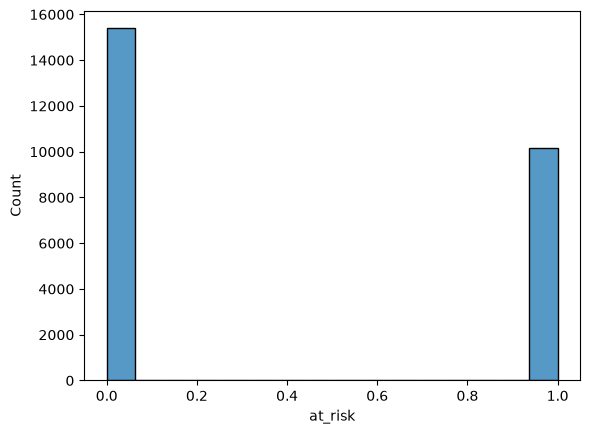

In [59]:
sns.histplot(data['at_risk'])

In [60]:
data.groupby("at_risk")[num_feature_columns].mean().round(1).T

at_risk,0,1
num_assessments_done,3.0,2.1
num_of_prev_attempts,0.1,0.2
date_registration,-66.5,-64.5
date_unregistration,0.0,45.9
studied_credits,73.7,77.9
avg_score,79.6,56.0
min_score,70.4,48.1
weighted_score,22.5,12.9
late_submissions,0.7,0.7
total_clicks,896.3,447.5


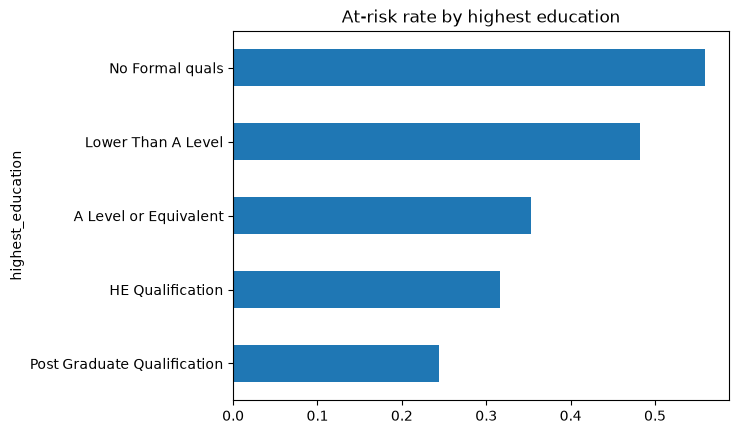

In [61]:
data.groupby("highest_education")["at_risk"].mean().sort_values().plot(kind="barh")
plt.title("At-risk rate by highest education")
plt.show()

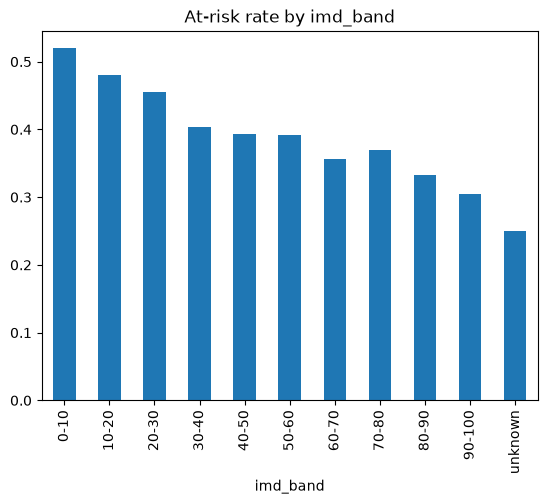

In [62]:
data.groupby("imd_band")["at_risk"].mean().plot(kind="bar")
plt.title("At-risk rate by imd_band")
plt.show()

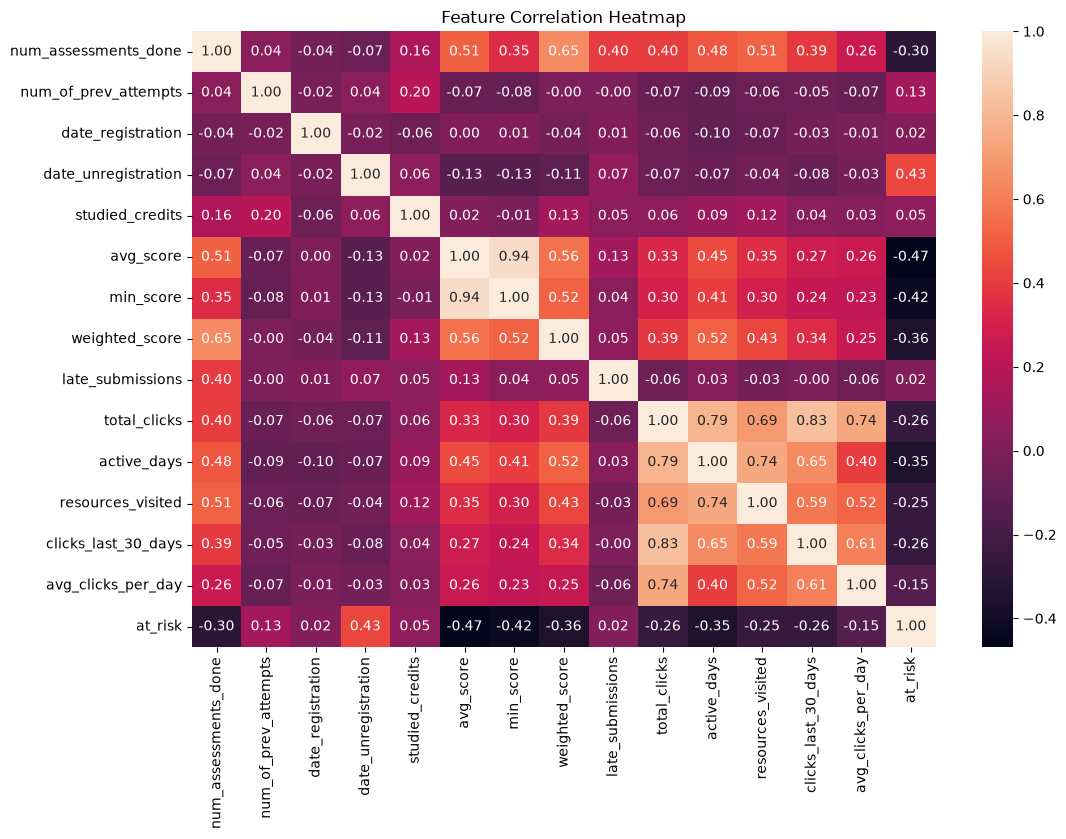

In [63]:
corr_matrix = data[num_feature_columns+['at_risk']].corr(numeric_only=True)

plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f')
plt.title("Feature Correlation Heatmap")
plt.show()

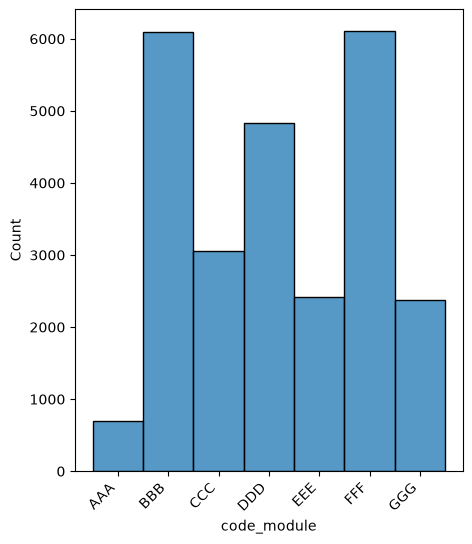

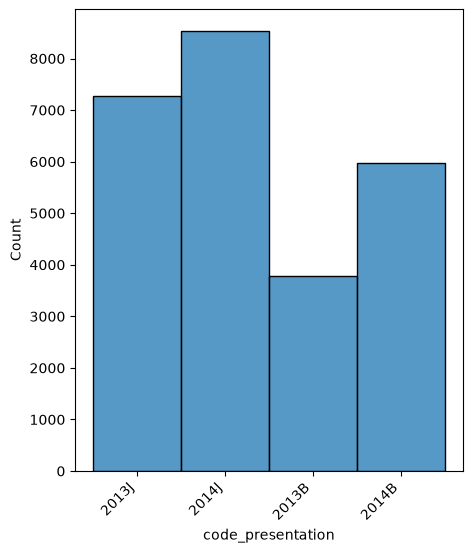

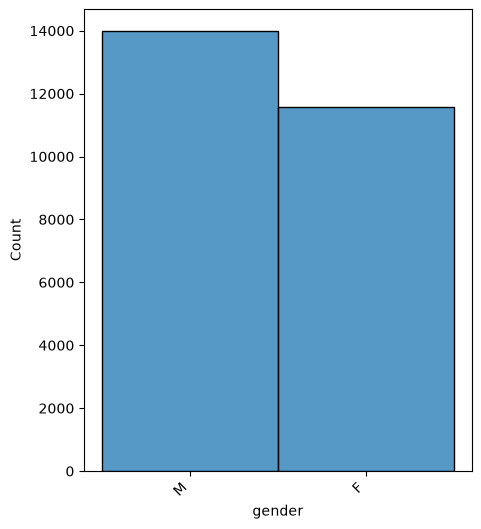

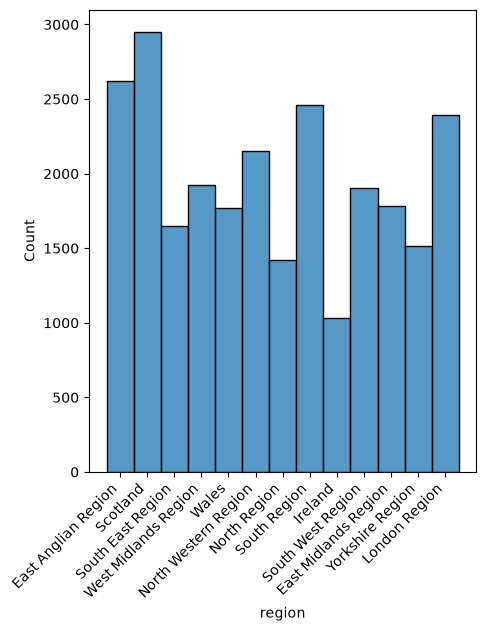

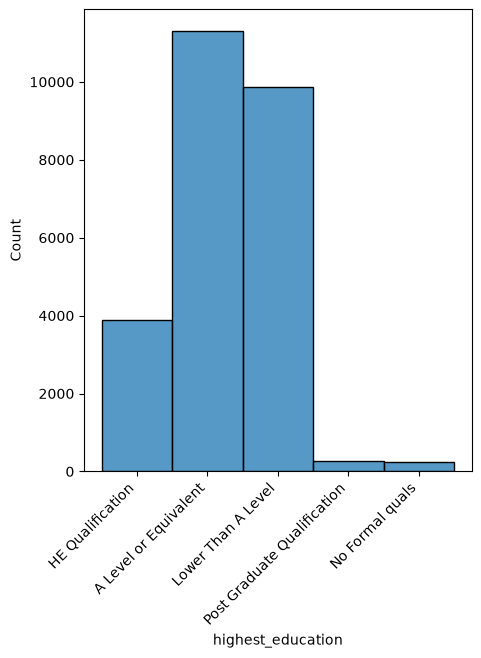

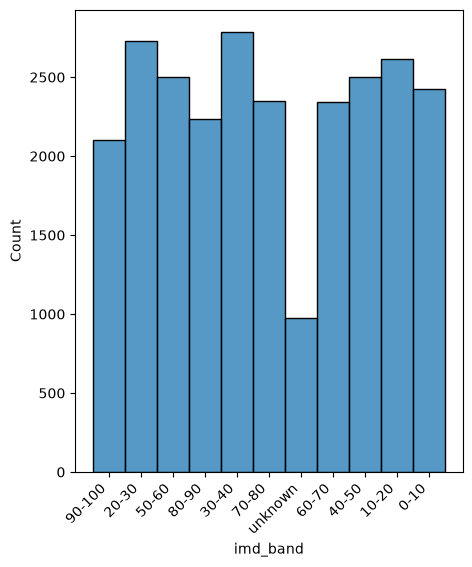

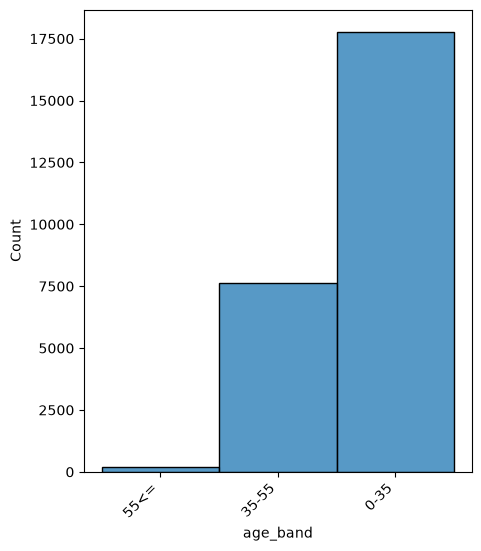

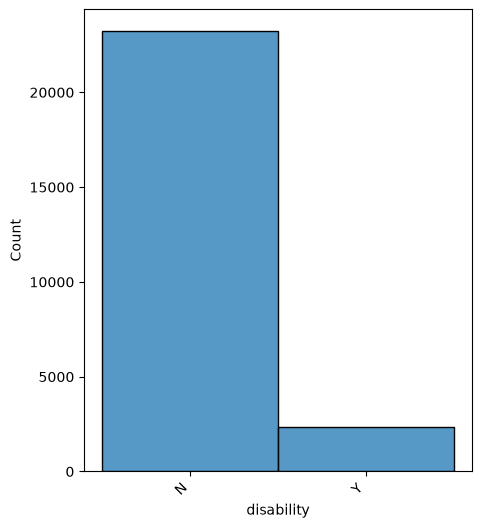

In [64]:
for i in cat_feature_columns:
    plt.figure(figsize=(5,6))
    plt.xticks(rotation=45,ha='right')
    sns.histplot(data[i])

- Avg_score vs at_risk (boxplot)

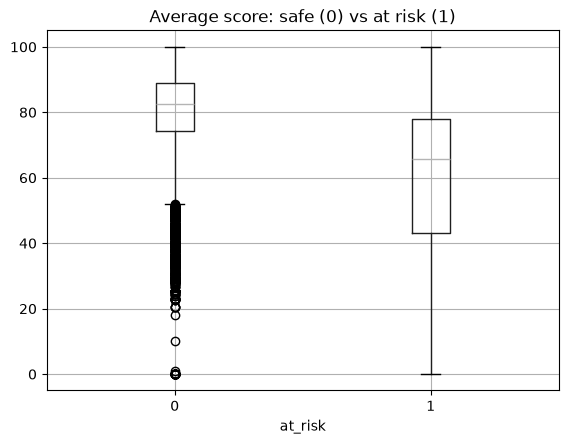

In [65]:
data.boxplot(column="avg_score", by="at_risk")
plt.title("Average score: safe (0) vs at risk (1)")
plt.suptitle("")
plt.show()

- total_clicks vs at_risk (boxplot)

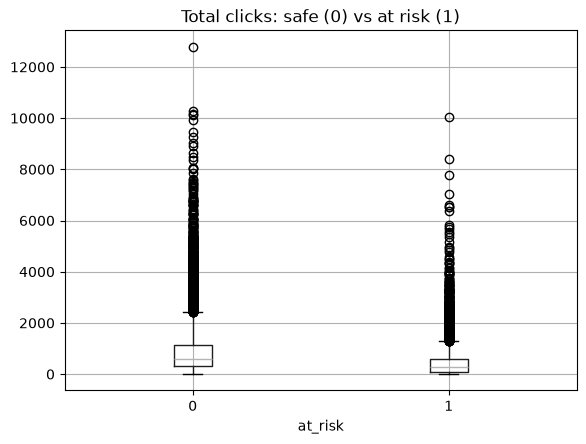

In [66]:
data.boxplot(column="total_clicks", by="at_risk")
plt.title("Total clicks: safe (0) vs at risk (1)")
plt.suptitle("")
plt.show()

- active_days vs at_risk

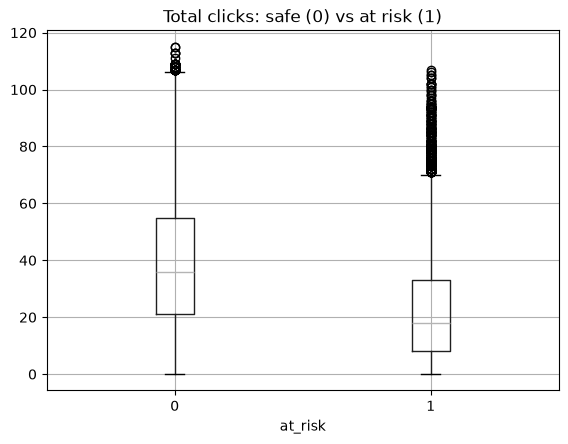

In [67]:
data.boxplot(column="active_days", by="at_risk")
plt.title("Total clicks: safe (0) vs at risk (1)")
plt.suptitle("")
plt.show()

- weighted_score vs at_risk

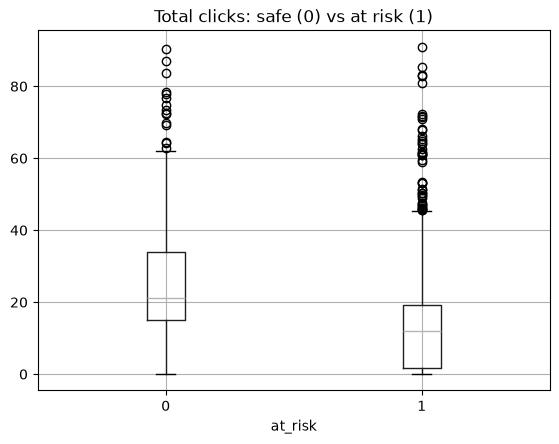

In [68]:
data.boxplot(column="weighted_score", by="at_risk")
plt.title("Total clicks: safe (0) vs at risk (1)")
plt.suptitle("")
plt.show()

- OutLiers

In [69]:
num_features = data[num_feature_columns].select_dtypes(include='number') #int64 or float64
Q1  = num_features.quantile(0.25)
Q3  = num_features.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = (num_features < lower_bound) | (num_features > upper_bound)
print(outliers.sum())

num_assessments_done    4844
num_of_prev_attempts    3198
date_registration        372
date_unregistration     3041
studied_credits         1274
avg_score               2215
min_score               2622
weighted_score            32
late_submissions        1529
total_clicks            1754
active_days              262
resources_visited        882
clicks_last_30_days     2299
avg_clicks_per_day       981
dtype: int64


In [70]:
data["no_assessment"] = (data["num_assessments_done"] == 0).astype(int)

In [71]:
print(data["no_assessment"].value_counts())

no_assessment
0    23836
1     1726
Name: count, dtype: int64


In [72]:
num_feature_columns.append("no_assessment")
print(num_feature_columns)

['num_assessments_done', 'num_of_prev_attempts', 'date_registration', 'date_unregistration', 'studied_credits', 'avg_score', 'min_score', 'weighted_score', 'late_submissions', 'total_clicks', 'active_days', 'resources_visited', 'clicks_last_30_days', 'avg_clicks_per_day', 'no_assessment']


In [73]:
cap_cols = ["total_clicks", "clicks_last_30_days",
            "resources_visited", "avg_clicks_per_day"]

In [74]:
caps = data[cap_cols].quantile(0.99)
print(caps)

total_clicks           4057.560000
clicks_last_30_days     952.000000
resources_visited       147.000000
avg_clicks_per_day       56.413309
Name: 0.99, dtype: float64


In [75]:
before = data[cap_cols].max()
before

total_clicks           12783.000000
clicks_last_30_days     4715.000000
resources_visited        313.000000
avg_clicks_per_day       224.666667
dtype: float64

In [76]:
data[cap_cols] = data[cap_cols].clip(upper=caps, axis=1)

In [77]:
print(pd.DataFrame({"before": before, "after": data[cap_cols].max()}))

                           before        after
total_clicks         12783.000000  4057.560000
clicks_last_30_days   4715.000000   952.000000
resources_visited      313.000000   147.000000
avg_clicks_per_day     224.666667    56.413309


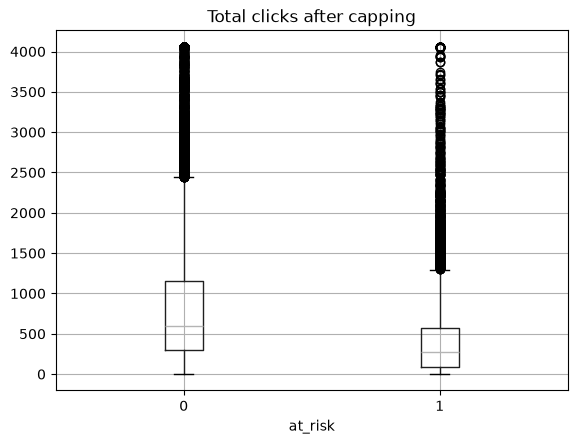

In [78]:
data.boxplot(column="total_clicks", by="at_risk")
plt.title("Total clicks after capping")
plt.suptitle("")
plt.show()

In [79]:
df_encoded = pd.get_dummies(data,columns=cat_feature_columns,drop_first=True,dtype=int)
df_encoded=df_encoded.drop(['final_result','id_student'],axis=1)
print(df_encoded.dtypes)
print(df_encoded.shape)

num_of_prev_attempts                               int64
studied_credits                                    int64
at_risk                                            int64
date_registration                                float64
date_unregistration                              float64
num_assessments_done                             float64
avg_score                                        float64
min_score                                        float64
weighted_score                                   float64
late_submissions                                 float64
total_clicks                                     float64
active_days                                      float64
resources_visited                                float64
clicks_last_30_days                              float64
has_unregistration                                 int64
avg_clicks_per_day                               float64
no_assessment                                      int64
code_module_BBB                

### 8. Choose X and Y

In [80]:

X = df_encoded.drop('at_risk',axis=1)
y = df_encoded["at_risk"]

In [81]:
print("X shape:", X.shape)
print("y shape:", y.shape)
X.sample(5)

X shape: (25562, 55)
y shape: (25562,)


,num_of_prev_attempts,studied_credits,date_registration,date_unregistration,num_assessments_done,avg_score,min_score,weighted_score,late_submissions,total_clicks,...,imd_band_40-50,imd_band_50-60,imd_band_60-70,imd_band_70-80,imd_band_80-90,imd_band_90-100,imd_band_unknown,age_band_35-55,age_band_55<=,disability_Y
926,3,120,-16.0,0.0,4.0,78.000000,66.0,29.280,1.0,267.0,...,0,0,1,0,0,0,0,0,0,0
14079,0,240,-37.0,0.0,3.0,67.666667,63.0,16.550,0.0,266.0,...,0,0,0,0,1,0,0,0,0,0
3593,0,60,-29.0,0.0,3.0,61.666667,60.0,14.910,3.0,176.0,...,0,0,0,1,0,0,0,0,0,0
4856,0,60,-32.0,0.0,4.0,82.000000,60.0,16.200,2.0,133.0,...,1,0,0,0,0,0,0,0,0,0
12941,0,60,-96.0,0.0,3.0,73.666667,71.0,29.275,0.0,182.0,...,0,0,0,0,0,0,0,0,0,0


- Split into train and test
- **Train set (80%)**
- **Test set (20%)**
- stratify=y keeps the same ratio of at-risk students in both sets.

In [82]:
from sklearn.model_selection import train_test_split

In [83]:

X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, stratify=y, random_state=42)
print("Train rows:", len(X_train))
print("Test rows :", len(X_test))

Train rows: 20449
Test rows : 5113


- Train Models

In [84]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)

In [85]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

models = {
    "Logistic Regression":  LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
}

In [86]:
result = []
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    acc = accuracy_score(y_test,y_pred)
    f1 = f1_score(y_test,y_pred)
    pre= precision_score(y_test, y_pred)
    rec= recall_score(y_test, y_pred)
    result.append( {
        "Model": name,
        "Accuracy": round(acc, 4),
        "Precision": round(pre, 4),
        "Recall": round(rec, 4),
        "F1": round(f1, 4)
    })

In [87]:
results_df = pd.DataFrame(result).set_index("Model")
results_df = results_df.sort_values("F1", ascending=False).round(4)
results_df

,Accuracy,Precision,Recall,F1
Model,,,,
Random Forest,0.8474,0.8829,0.7112,0.7878
Logistic Regression,0.8396,0.8649,0.7078,0.7785
Decision Tree,0.8222,0.9098,0.6144,0.7335
KNN,0.7772,0.8045,0.5820,0.6754


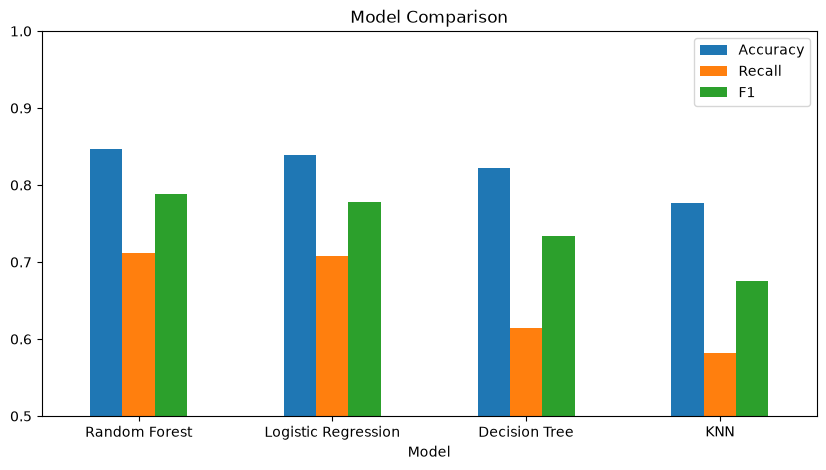

In [88]:
results_df[["Accuracy", "Recall", "F1"]].plot(kind="bar", figsize=(10, 5))
plt.title("Model Comparison")
plt.ylim(0.5, 1)
plt.xticks(rotation=0)
plt.show()

- BEST Model

In [89]:
best_name = results_df.index[0]
best_model = models[best_name]
print("Best model:", best_name)

Best model: Random Forest


In [90]:
y_pred = best_model.predict(X_test)
print(classification_report(y_test, y_pred, target_names=["Safe (0)", "At Risk (1)"]))

              precision    recall  f1-score   support

    Safe (0)       0.69      1.00      0.82      3077
 At Risk (1)       1.00      0.31      0.48      2036

    accuracy                           0.73      5113
   macro avg       0.84      0.66      0.65      5113
weighted avg       0.81      0.73      0.68      5113



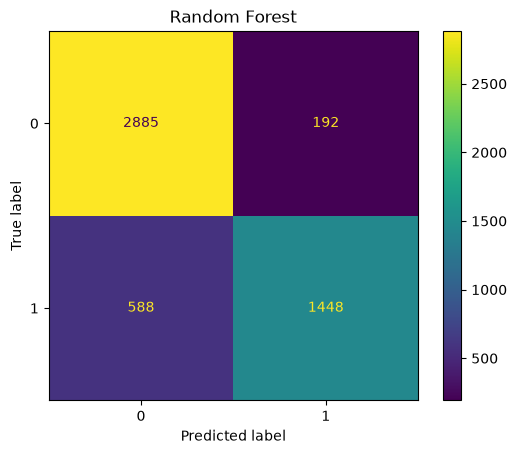

In [91]:
ConfusionMatrixDisplay.from_estimator(best_model, X_test_scaled, y_test)
plt.title(best_name)
plt.show()

- Cross Validation applying On All Models

In [92]:
from sklearn.model_selection import cross_val_score

for name, model in models.items():
    f1_scores = cross_val_score(model, X, y, cv=5, scoring="f1")
    recall_scores = cross_val_score(model, X, y, cv=5, scoring="recall")
    print(
        f"{name}|"
        f"Recall: {recall_scores.mean():.4f}|"
        f"F1: {f1_scores.mean():.4f}"
    )

Logistic Regression|Recall: 0.6636|F1: 0.7036
KNN|Recall: 0.6617|F1: 0.6890
Decision Tree|Recall: 0.6857|F1: 0.7086
Random Forest|Recall: 0.7382|F1: 0.7207


- Probabilities using CV

In [93]:
from sklearn.model_selection import cross_val_predict
train_probs = cross_val_predict(best_model, X_train_scaled, y_train, cv=5, method="predict_proba")[:, 1]

- Testing On Different Threshold

In [94]:
rows = []

for t in [0.25, 0.30, 0.35, 0.40, 0.45, 0.50]:
    pred = (train_probs >= t).astype(int)
    rows.append({
        "Threshold": t,
        "Precision": precision_score(y_train, pred),
        "Recall": recall_score(y_train, pred),
        "F1": f1_score(y_train, pred),
    })

threshold_df = pd.DataFrame(rows).round(3)
threshold_df

,Threshold,Precision,Recall,F1
0,0.25,0.669,0.883,0.761
1,0.30,0.720,0.849,0.779
2,0.35,0.767,0.818,0.791
3,0.40,0.808,0.782,0.794
4,0.45,0.845,0.751,0.795
5,0.50,0.877,0.719,0.790


In [95]:
chosen_threshold = 0.35

In [96]:
test_probs = best_model.predict_proba(X_test_scaled)[:, 1]
final_pred = (test_probs >= chosen_threshold).astype(int)

print(classification_report(y_test, final_pred, target_names=["Safe (0)", "At Risk (1)"]))

              precision    recall  f1-score   support

    Safe (0)       0.87      0.84      0.85      3077
 At Risk (1)       0.77      0.81      0.79      2036

    accuracy                           0.83      5113
   macro avg       0.82      0.82      0.82      5113
weighted avg       0.83      0.83      0.83      5113



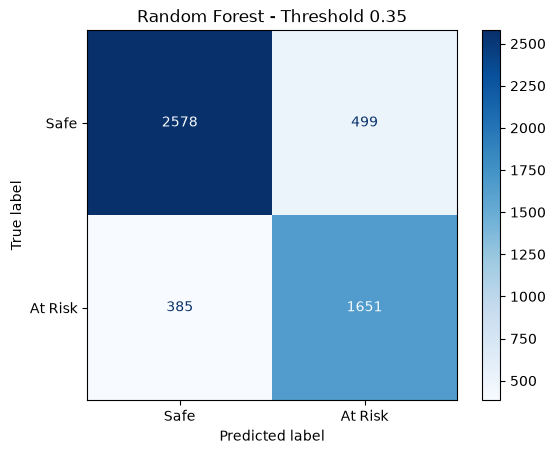

In [97]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, final_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Safe","At Risk"]
)

disp.plot(cmap="Blues")
plt.title("Random Forest - Threshold 0.35")
plt.show()

- Hyperparameters Tuned in all Models

In [98]:
from scipy.stats import randint
param_grids = {
    "Logistic Regression": {"logisticregression__C": [0.01, 0.1, 1, 10, 100]},
    "KNN": {"kneighborsclassifier__n_neighbors": [3, 5, 7, 11, 15, 21]},
    "Decision Tree": {"max_depth": [3, 5, 7, 10, None], "min_samples_leaf": [1, 10, 30, 50]},
    "Random Forest": {"n_estimators": [100, 200, 300], "max_depth": [5, 10, 15, None], "min_samples_leaf": randint(1,6),"min_samples_split":randint(2,11),"max_features":["sqrt","log2"]},
}

In [99]:
from sklearn.model_selection import RandomizedSearchCV

search = RandomizedSearchCV(
    estimator=models[best_name],
    param_distributions=param_grids[best_name],
    n_iter = 10,
    cv=3,
    scoring="recall",
    n_jobs=-1,
    random_state=42,
     verbose=1
)
search.fit(X_train, y_train)

Fitting 3 folds for each of 10 candidates, totalling 30 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': [5, 10, ...], 'max_features': ['sqrt', 'log2'], 'min_samples_leaf': <scipy.stats....001E4AC676120>, 'min_samples_split': <scipy.stats....001E4AC526E90>, ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'recall'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``re

In [100]:
print("Best params:", search.best_params_)
print("Best CV Recall :", round(search.best_score_, 4))

Best params: {'max_depth': None, 'max_features': 'log2', 'min_samples_leaf': 1, 'min_samples_split': 4, 'n_estimators': 100}
Best CV Recall : 0.715


In [101]:
tuned_model = search.best_estimator_
print(classification_report(y_test, tuned_model.predict(X_test)))

              precision    recall  f1-score   support

           0       0.83      0.94      0.88      3077
           1       0.88      0.71      0.78      2036

    accuracy                           0.85      5113
   macro avg       0.85      0.82      0.83      5113
weighted avg       0.85      0.85      0.84      5113



In [102]:
import joblib

joblib.dump(tuned_model, "best_model.pkl")
print("Model saved")

Model saved
